# **시계열 분석**

### (1) 시계열 문제

- 시계열 분석 : 시간에 따라 변하는 데이터를 사용하여 추이를 분석하는 것
- ex) 주가/환율 변동, 기온/습도 변화 등
  - 불규칙 변동 : 시간에 따른 규칙직인 움직임과 달리 어떤 규칙성이 없어 예측 불가능하고 우연적으로 발생하는 변동
  - 추세 변동 : 장기적인 변화 추세 -> 장기간에 걸쳐 지속적으로 증가, 감소하거나 또는 일정한 상태를 유지하려는 성향
  - 순환 변동 : 대체로 2~3년 정도의 일정한 기간을 주기로 순환적으로 나타나는 변도어
  - 계절 변동 : 계절적 영향과 사회적 관습에 따라 1년 주기로 발생하는 것

- 규칙적 시계열 : 트렌드와 분산이 불변하는 데이터
- 불규칙적 시계열 : 트렌드 혹은 분산이 변화하는 시계열 데이터

### (2) AR, MA, ARMA, ARIMA

**AR 모델**
- 이전 관측 값이 이후 관측 값에 영향을 준다는 아이디어에 대한 모형 (자기 회귀 모델)

$$
Z_t = \phi_1 Z_{t-1} + \phi_2 Z_{t-2} + \cdots + \phi_p Z_{t-p} + a_t
$$

- $Z_t$: 현재 시점의 시계열 데이터
- $\phi_i$: 과거 시점의 데이터가 현재에 미치는 영향을 나타내는 모수(계수)
- $Z_{t-i}$: $i$시점 이전의 과거 시계열 데이터
- $a_t$: 현재 시점의 오차항으로, 백색 잡음(White Noise)을 의미

**MA 모델**
- 트렌드가 변화하는 상황에 적합한 이동 평균 모델
- 이동 평균 모델 : 시계열을 따라 윈도우 크기만큼 슬라이딩 되는 모델

$$
Z_t = \theta_1 a_{t-1} + \theta_2 a_{t-2} + \cdots + \theta_p a_{t-p} + a_t
$$
- $Z_t$: 현재 시점의 시계열 데이터
- $\theta_i$: 과거 오차항이 현재 데이터에 미치는 영향을 나타내는 모수(계수)
- $a_{t-i}$: $i$시점 이전의 오차항
- $a_t$: 현재 시점의 오차항으로, 백색 잡음(White Noise)을 의미

**ARMA 모델**
- AR과 MA를 섞은 모델 (자기 회귀 이동 평균 모델)

$$
Z_t = a + \phi_1 Z_{t-1} + \cdots + \phi_p Z_{t-p}
+ \theta_1 a_{t-1} + \cdots + \theta_q a_{t-q} + a_t
$$

**ARIMA 모델**
- 자기 회귀와 이동 평균을 둘 다 고려하는 모형 (자기 회귀 누적 이동 평균 모델)
- ARIMA(p, d, q)
  - p: 자기 회귀 차수
  - d: 차분 차수
  - q: 이동 평균 차수

[statsmodels 라이브러리]
- 검정 및 추정
- 회귀 분석
- 시계열 분석

In [1]:
!pip install statsmodels

In [10]:
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 30.92 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


/tmp/ipykernel_612/286472699.py:11: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0], index_col=0, date_parser=parser)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   36
Model:                 ARIMA(5, 1, 0)   Log Likelihood                -199.651
Date:                Thu, 12 Nov 2026   AIC                            411.302
Time:                        11:49:25   BIC                            420.634
Sample:                    01-01-1991   HQIC                           414.523
                         - 12-01-1993                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8788      0.227     -3.876      0.000      -1.323      -0.434
ar.L2         -0.2787      0.232     -1.203      0.229      -0.733       0.176
ar.L3         -0.0076      0.270     -0.028      0.9

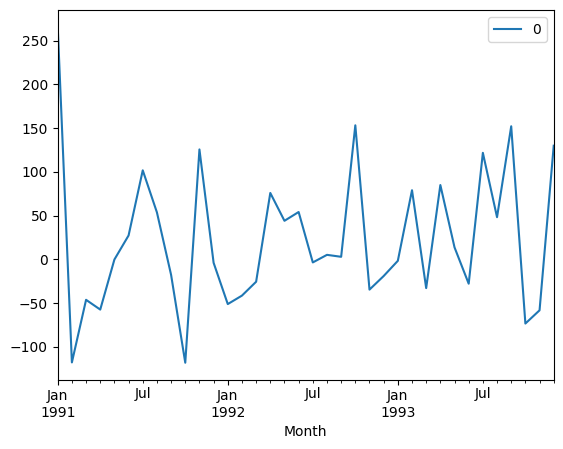

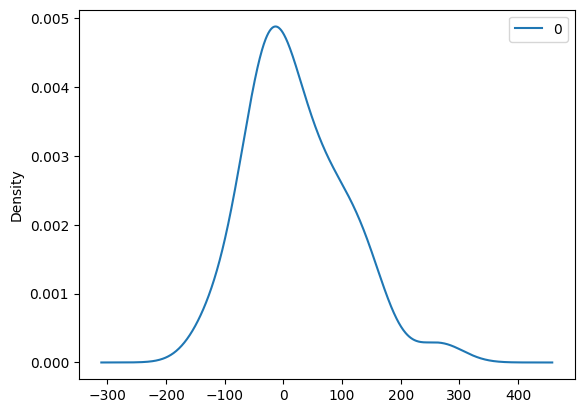

                0
count   36.000000
mean    22.459086
std     82.505331
min   -118.213281
25%    -33.308343
50%      1.361178
75%     76.704967
max    266.000000


In [13]:
# ARIMA() 함수를 호출하여 sales 데이터셋에 대한 예측
from pandas import read_csv
from datetime import datetime
from pandas import DataFrame
from statsmodels.tsa.arima.model import ARIMA
from matplotlib import pyplot

def parser(x):
  return datetime.strptime('199'+x, '%Y-%m')

series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0], index_col=0, date_parser=parser)
model = ARIMA(series, order=(5,1,0))
model_fit = model.fit()
print(model_fit.summary())
residuals = DataFrame(model_fit.resid)
residuals.plot()
pyplot.show()
residuals.plot(kind='kde')
pyplot.show()
print(residuals.describe())

/tmp/ipykernel_612/463475367.py:12: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0], index_col=0, date_parser=parser)


predicted=352.855343, expected=346.300000
predicted=277.398036, expected=329.700000
predicted=368.753734, expected=445.400000
predicted=331.773635, expected=325.900000
predicted=372.070407, expected=449.300000
predicted=360.020872, expected=411.300000
predicted=454.526230, expected=417.400000
predicted=388.690699, expected=545.500000
predicted=437.632447, expected=477.600000
predicted=516.437624, expected=687.000000
predicted=520.916191, expected=435.300000
predicted=675.594647, expected=587.300000
predicted=505.201016, expected=676.900000
Test MSE: 9118.818


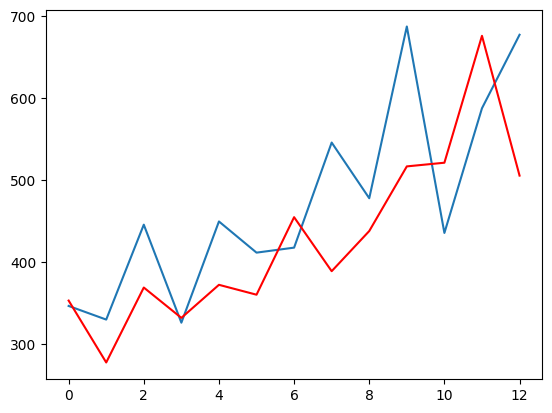

In [15]:
# statsmodels 라이브러리를 이용한 sales 데이터셋 예측
import numpy as np
from pandas import read_csv
from datetime import datetime
from matplotlib import pyplot
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

def parser(x):
    return datetime.strptime('199' + x, '%Y-%m')

series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0], index_col=0, date_parser=parser)

X = series.values.flatten()
X = np.nan_to_num(X)
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]  # train과 test로 데이터셋 분리

history = [x for x in train]
predictions = list()

for t in range(len(test)):  # test 데이터셋의 길이(13)만큼 반복하여 수행
    model = ARIMA(history, order=(5, 1, 0))  # ARIMA() 함수 호출
    model_fit = model.fit()
    output = model_fit.forecast()  # forecast() 메서드를 사용하여 예측 수행
    yhat = output[0]  # 모델 출력 결과를 yhat에 저장
    predictions.append(yhat)
    obs = test[t]
    history.append(obs)
    # 모델 실행 결과를 predicted로 출력하고,
    # test로 분리해 둔 데이터를 expected로 사용하여 출력
    print('predicted=%f, expected=%f' % (yhat, obs))
error = mean_squared_error(test, predictions)  # 손실 함수로 평균 제곱 오차 사용
print('Test MSE: %.3f' % error)
pyplot.plot(test)
pyplot.plot(predictions, color='red')
pyplot.show()

### (3) 순환 신경망(RNN)

- RNN : 시간적으로 연속성이 있는 데이터를 처리하려고 고안된 인공 신경망
- '기억'을 갖고 새로운 입력이 네트워크로 들어올 때마다 기억은 조금씩 수정되며 결국 최종적으로 남겨진 기억이 모든 입력 전체를 요약한 정보가 됨

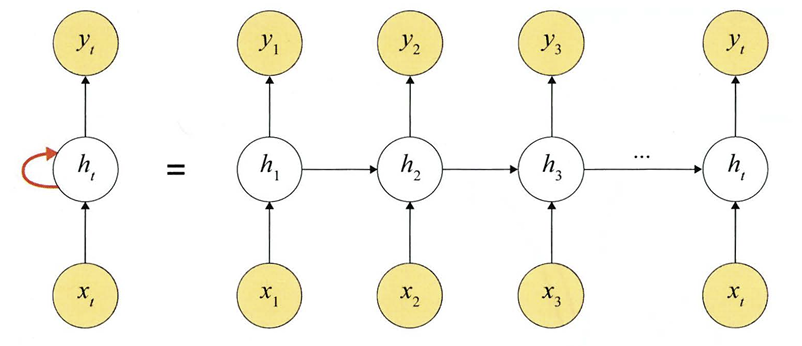

- 일대일 : 순환이 없는 순방향 네트워크
- 일대다 : 입력이 하나이고 출력이 다수인 구조
- 다대일 : 입력이 다수이고 출력이 하나인 구조

In [17]:
'''
self.em = nn.Embedding(len(TEXT.vocab.stoi), embedding_dim)  # 임베딩 처리
self.rnn = nn.RNNCell(input_dim, hidden_size)  # RNN 적용
self.fc1 = nn.Linear(hidden_size, 256)  # 완전연결층
self.fc2 = nn.Linear(256, 3)  # 출력층
'''

'\nself.em = nn.Embedding(len(TEXT.vocab.stoi), embedding_dim)  # 임베딩 처리\nself.rnn = nn.RNNCell(input_dim, hidden_size)  # RNN 적용\nself.fc1 = nn.Linear(hidden_size, 256)  # 완전연결층\nself.fc2 = nn.Linear(256, 3)  # 출력층\n'

- 다대다 : 입력과 출력이 다수인 구조

- 동기화 다대다 : 입력과 출력이 다수인 구조로 문장에서 다음에 나올 단어를 예측

[RNN 모델 유형]
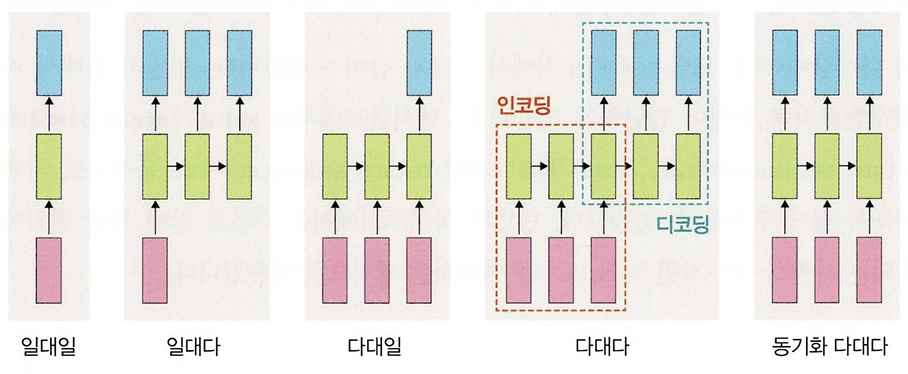

**RNN 계층과 셀**
- RNN 계층 : 입력된 배치 순서대로 모두 처리
- RNN 셀 : 오직 하나의 단계만 처리

[셀 유형]
- nn.RNNCell: SimpleRNN 계층에 대응되는 RNN 셀
- nn.GRUCell: GRU 계층에 대응되는 GRU 셀
- nn.LSTMCell: LSTM 계층에 대응되는 LSTM 셀